# Титаник: олон хувьсагчтай дүрслэлийн 7 аргачлал ба 7 далд олдвор

**Онолын үндэс:** C. Tominski, H. Schumann — *Interactive Visual Data Analysis* (2020); J. Schwabish — *Better Data Visualizations* (2021).

“Эмэгтэйчүүд ба 1-р анги илүү амьд үлдсэн” гэдэг нь хүн бүрийн мэддэг дүгнэлт. Энэ notebook-ийн аргачлал бүр **тэр ерөнхий дүгнэлтийн цаана нуугдсан нэг олдвор**-ыг харуулна:

| № | Аргачлал | Олдвор |
|---|---|---|
| 1 | Mosaic plot | 3-р ангийн эмэгтэйчүүдийн хувь заяаг **суусан боомт** нь шийдсэн: Куинстаун **73%**, Саутгемптон **38%** |
| 2 | Parallel coordinates | 3-р ангийн хамгийн **“үнэтэй”** тасалбар = хамгийн **том гэр бүл** — тэдний ердөө **7%** амьд |
| 3 | Scatter plot matrix | 1-р ангийн эрэгтэйчүүдийг **нас** ялгасан: 60+ насны **14-өөс 2** нь л амьд |
| 4 | Heatmap | **2-р ангийн** 18–30 насны эрэгтэйчүүд хамгийн муу: **41-ээс 1** (3-р ангийнхнаас ч муу) |
| 5 | Small multiples | Гэр бүл **эрэгтэйд тусалж**, 3-р ангийн **эмэгтэйд саад** болсон |
| 6 | Star glyph | Шербурын өндөр амьд үлдэлт (55%) — **зорчигчдын тал нь 1-р анги** байсных |
| 7 | Pixel-based | **Үнэгүй** (£0) тасалбартай 15 хүн — бүгд эрэгтэй, **1-р ангийнх ч** байсан, **14** нь амь үрэгдсэн |

## Өгөгдлийн бүтэц

Tominski, Schumann нарын тодорхойлолтоор **олон хувьсагчтай өгөгдөл** нь нэг нэгж (зорчигч) дээр $A = \{a_1, \dots, a_m\}$, $m \ge 3$ хувьсагч хэмжигдсэн бүтэц юм.

| Түвшин | Хувьсагч | Тохирох визуал суваг |
|---|---|---|
| Номинал | `Survived`, `Sex`, `Embarked` (C/Q/S) | өнгөний туяа, панел |
| Эрэмбэт | `Pclass` (1–3) | байрлал, гэрэлтэлт |
| Тоон | `Age`, `Fare`, `FamilySize` = SibSp + Parch + 1 | байрлал, урт |

## График байгуулах дүрэм

1. **Нэг график = нэг олдвор.** Гарчиг нь олдворыг шууд хэлнэ; графикт үүнээс өөр текст бараг байхгүй.
2. **“Start with gray” (Schwabish):** **цэнхэр = амьд үлдсэн**, **саарал = амь үрэгдсэн**. Бүх зурагт ижил.
3. **Cleveland & McGill:** гол харьцуулалт **байрлал/урт**-аар; баганыг 0-ээс; `Fare`-г лог масштабаар.
4. **Шаардлагагүйг хасах:** хүрээ, сүлжээ, тэмдэглэгээг хамгийн бага. Дэлгэрэнгүй (n, хассан мөр) нь графикийн доорх текстэд.
5. **Хэмжээ → нэг туяа** (цайвар → бараан), солонгон палитргүй. Цэнхэр–саарал хос нь өнгө ялгах чадвар сул хүнд ч ялгагдана.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, BoundaryNorm, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

SURFACE = '#fcfcfb'; INK = '#0b0b0b'; INK2 = '#52514e'; MUTED = '#8a8984'; GRID = '#e6e5e1'
C_SURV = '#2a78d6'   # амьд үлдсэн
C_DIED = '#a3a29c'   # амь үрэгдсэн
BLUES = LinearSegmentedColormap.from_list('blues', ['#e3eefc', '#86b6ef', '#2a78d6', '#184f95', '#0d366b'])
VIOLET = LinearSegmentedColormap.from_list('violet', ['#eeebfc', '#a99ef0', '#6250d6', '#3a2c9c', '#1f175c'])

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.edgecolor': MUTED, 'axes.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False, 'figure.dpi': 110,
})

def header(fig, title, gap=0.75):
    h = fig.get_figheight()
    fig.text(0.012, 1 - 0.12 / h, title, ha='left', va='top', fontsize=14, fontweight='bold', color=INK)
    fig.subplots_adjust(top=1 - gap / h)

def legend(fig, handles=None):
    h = handles or [Patch(color=C_SURV, label='Амьд үлдсэн'), Patch(color=C_DIED, label='Амь үрэгдсэн')]
    fig.legend(handles=h, ncol=len(h), fontsize=10, handlelength=1.2, loc='upper left',
               bbox_to_anchor=(0.006, 1 - 0.42 / fig.get_figheight()))   # гарчгийн доор

try:
    df = sns.load_dataset('titanic')
except Exception:
    df = pd.read_csv('titanic.csv')
df['FamilySize'] = df['sibsp'] + df['parch'] + 1
PORT = {'Cherbourg': 'Шербур', 'Queenstown': 'Куинстаун', 'Southampton': 'Саутгемптон'}
df['port'] = df['embark_town'].map(PORT)
print(f'Зорчигч: {len(df)}, амьд үлдсэн: {df.survived.mean():.1%}')

Зорчигч: 891, амьд үлдсэн: 38.4%


---
## Аргачлал 1: Mosaic plot — шатлалтай үүрэн дүрслэл

**Онолын ангилал:** Tominski & Schumann §3.2.6 *Nested visualization*.

| Тэмдэглэгээ | Визуал суваг |
|---|---|
| 2D тэгш өнцөгт нүд | мөрийн **өндөр** = боомтоос суусан тоо · нүдний **өргөн** = хүйсийн хувь · **цэнхэр өндөр** = амьд үлдсэн хувь |

*Өгөгдөл:* зөвхөн 3-р анги (n = 491). Ингэснээр ангийн нөлөөг хасаж, боомтын ялгааг цэвэр харна.

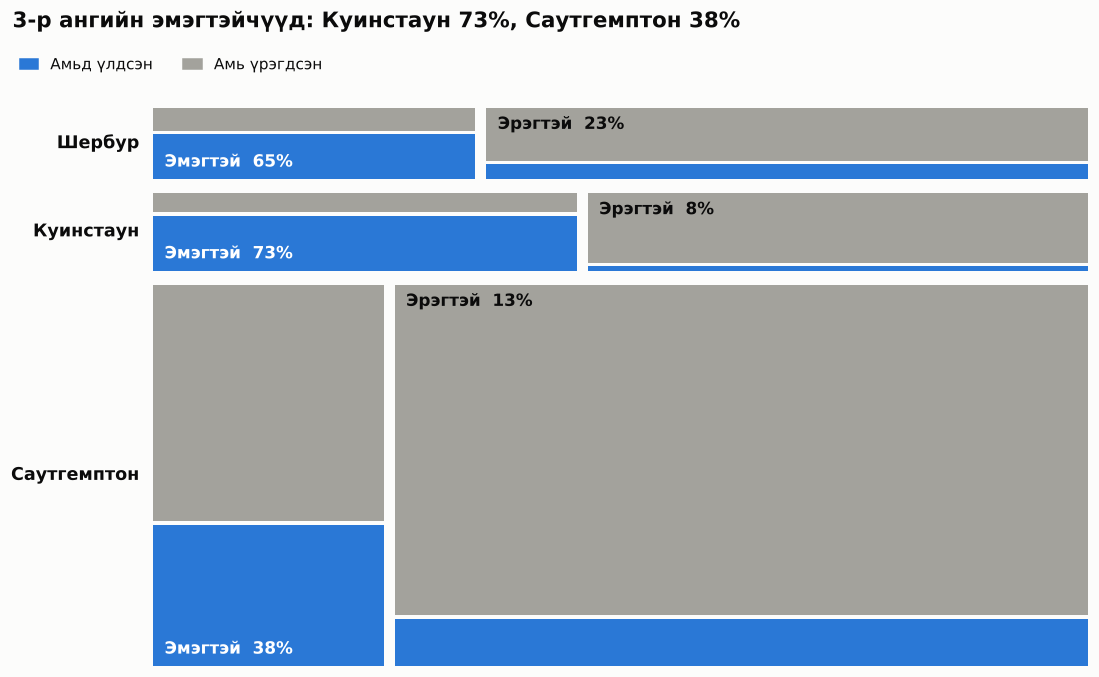

In [2]:
t = df[(df.pclass == 3) & df.port.notna()]
order = ['Шербур', 'Куинстаун', 'Саутгемптон']
gy, gx, gs = 0.025, 0.012, 0.006
avail = 1 - gy * (len(order) - 1)

fig, ax = plt.subplots(figsize=(10, 6.2))
y_top = 1.0
for p in order:
    tp = t[t.port == p]
    h = avail * len(tp) / len(t)
    y0 = y_top - h; x0 = 0
    for s, s_mn in [('female', 'Эмэгтэй'), ('male', 'Эрэгтэй')]:
        ts = tp[tp.sex == s]
        w = (1 - gx) * len(ts) / len(tp)
        r = ts.survived.mean()
        ax.add_patch(Rectangle((x0, y0), w, h * r - gs / 2, color=C_SURV, lw=0))
        ax.add_patch(Rectangle((x0, y0 + h * r + gs / 2), w, h * (1 - r) - gs / 2, color=C_DIED, lw=0))
        inside = r >= 0.3
        ax.text(x0 + 0.012, y0 + 0.015 if inside else y0 + h - 0.015, f'{s_mn}  {r:.0%}',
                va='bottom' if inside else 'top', fontsize=11, fontweight='bold', color='white' if inside else INK)
        x0 += w + gx
    ax.text(-0.015, y0 + h / 2, p, ha='right', va='center', fontsize=11.5, fontweight='bold')
    y_top = y0 - gy
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
legend(fig)
header(fig, '3-р ангийн эмэгтэйчүүд: Куинстаун 73%, Саутгемптон 38%', gap=1.0)
fig.subplots_adjust(left=0.14, right=0.99, bottom=0.02)
plt.show()

**Олдвор**
- Нэг ангийн, нэг хүйсийн эмэгтэйчүүд байтал **Куинстаунаас** (Ирланд) суусан 3-р ангийн эмэгтэйчүүдийн **73%** амьд үлдсэн бол **Саутгемптоноос** (Англи) суусных ердөө **38%** — бараг **2 дахин** ялгаатай.
- Эсрэгээрээ Куинстауны эрэгтэйчүүд хамгийн муу (**8%**): тэнд хүйсийн ялгаа хамгийн их (73% vs 8%).
- Саутгемптоны мөр хамгийн өндөр (353 хүн) бөгөөд эрэгтэйчүүдийн нүд бараг бүхэлдээ саарал — 3-р ангийн амь үрэгдэгсдийн гол хэсэг.
- *Шалтгаан нь гэр бүлд байна:* Куинстауны 3-р ангийн эмэгтэйчүүдийн **76%** нь ганцаараа явсан, 5+ гэр бүлтэй нь ердөө **3%**. Саутгемптоных ганцаараа **34%**, 5+ гэр бүлтэй **30%**. Олон хүүхэдтэй эхчүүд амьд үлдэх магадлал бага байсныг Аргачлал 2, 5 харуулна.

**Давуу тал:** Ангиллын 3 хувьсагчийн (боомт × хүйс × хувь заяа) **нөхцөлт давтамжийг** талбайн харьцаагаар нэг зурагт харуулна. Нүдний **талбай = хүний тоо**, **цэнхэр өндөр = хувь** тул “хувь өндөр ч цөөн” (Куинстауны эмэгтэйчүүд, n = 33) ба “хувь бага ч олон” (Саутгемптоны эрэгтэйчүүд, n = 265) бүлгийг зэрэг ялгана.

---
## Аргачлал 2: Parallel coordinates — зэрэгцээ координат

**Онолын ангилал:** Tominski & Schumann §3.2.3 *Polyline-based*; Schwabish — *Relationship charts*.

| Тэмдэглэгээ | Визуал суваг |
|---|---|
| 1D шугам (нэг зорчигч = нэг шугам) | 4 зэрэгцээ тэнхлэг дээрх **байрлал**: Хүйс → Гэр бүл → Үнэ (лог) → Хувь заяа · **өнгө** = хувь заяа (саарлыг эхэлж, цэнхрийг дээр нь) |

*Өгөгдөл:* 3-р анги (n = 491). Хүйс, гэр бүл, хувь заяанд бага зэрэг jitter нэмсэн.

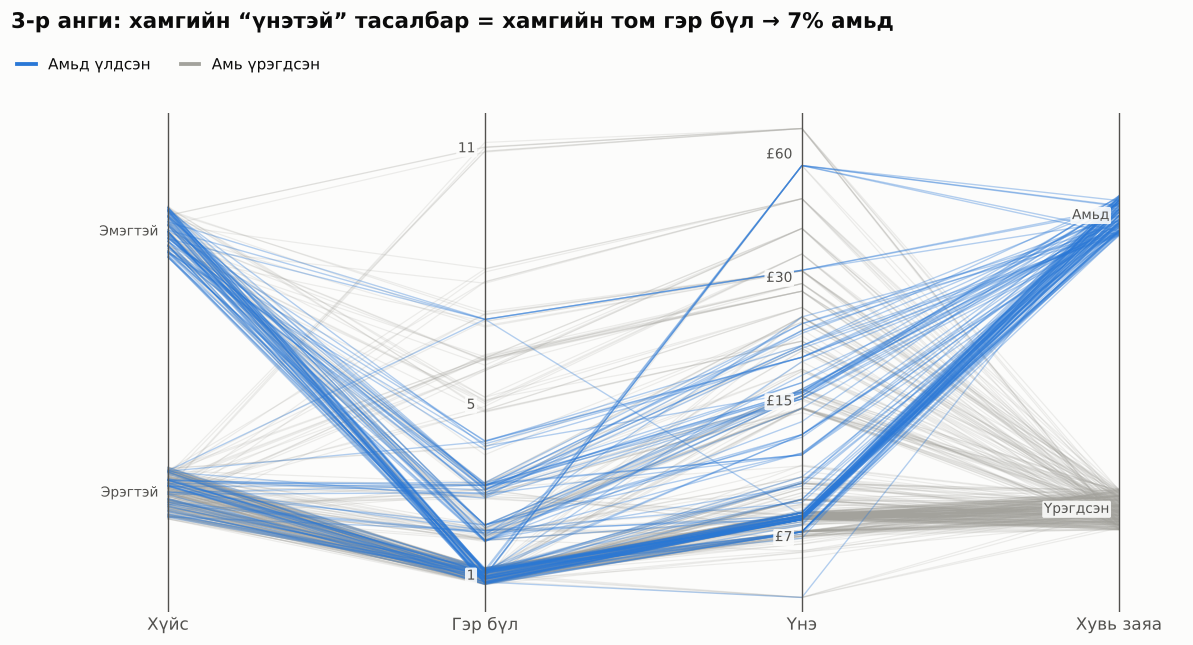

In [3]:
t = df[df.pclass == 3].copy()
rng = np.random.default_rng(4)
fare_l = np.log10(t.fare.clip(lower=5))
A = [  # (нэр, утга, доод, дээд, тэмдэглэгээ)
    ('Хүйс',      (t.sex == 'female') + rng.uniform(-.1, .1, len(t)), -0.4, 1.4, {1: 'Эмэгтэй', 0: 'Эрэгтэй'}),
    ('Гэр бүл',   t.FamilySize + rng.uniform(-.2, .2, len(t)), 0.5, 11.5, {1: '1', 5: '5', 11: '11'}),
    ('Үнэ',       fare_l, np.log10(5), np.log10(70), {np.log10(v): f'£{v}' for v in [7, 15, 30, 60]}),
    ('Хувь заяа', t.survived + rng.uniform(-.07, .07, len(t)), -0.3, 1.3, {1: 'Амьд', 0: 'Үрэгдсэн'}),
]
Y = np.column_stack([(v - lo) / (hi - lo) for _, v, lo, hi, _ in A])
xs = np.arange(len(A)); surv = t.survived.values == 1

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(xs, Y[~surv].T, color=C_DIED, alpha=0.18, lw=0.8)
ax.plot(xs, Y[surv].T, color=C_SURV, alpha=0.35, lw=0.9)
for i, (name, _, lo, hi, ticks) in enumerate(A):
    ax.axvline(i, color=INK2, lw=0.9)
    for tv, tl in ticks.items():
        ax.text(i - 0.03, (tv - lo) / (hi - lo), tl, ha='right', va='center', fontsize=9, color=INK2,
                bbox=dict(boxstyle='round,pad=0.12', fc=SURFACE, ec='none', alpha=0.9))
ax.set_xticks(xs, [a[0] for a in A], fontsize=11); ax.tick_params(axis='x', length=0)
ax.set_yticks([]); ax.spines[['left', 'bottom']].set_visible(False)
ax.set_xlim(-0.35, len(xs) - 0.8); ax.set_ylim(-0.03, 1.03)
legend(fig, [Line2D([], [], color=C_SURV, lw=2.5, label='Амьд үлдсэн'), Line2D([], [], color=C_DIED, lw=2.5, label='Амь үрэгдсэн')])
header(fig, '3-р анги: хамгийн “үнэтэй” тасалбар = хамгийн том гэр бүл → 7% амьд', gap=1.05)
fig.subplots_adjust(left=0.05, right=0.98, bottom=0.07)
plt.show()

In [4]:
t['Гэр бүл'] = pd.cut(t.FamilySize, [0, 1, 4, 20], labels=['Ганцаараа', '2–4', '5+'])
t.groupby('Гэр бүл', observed=True).agg(n=('survived', 'size'), **{'Медиан үнэ £': ('fare', 'median'),
                                        'Амьд үлдсэн': ('survived', 'mean')}).round(2)

,n,Медиан үнэ £,Амьд үлдсэн
Гэр бүл,,,
Ганцаараа,324,7.90,0.21
2–4,113,15.50,0.41
5+,54,31.33,0.07


**Олдвор**
- **Гэр бүл → Үнэ** хооронд шугамууд бараг хэвтээ, зэрэгцээ урсдаг (корреляц **r = 0.81**): `Fare` нь **нэг хүний биш, нэг тасалбарын** үнэ бөгөөд гэр бүл нэг тасалбараар явдаг байсан. Тиймээс 3-р ангийн “үнэтэй” тасалбар (£31, 2-р ангийн дундаж үнээс өндөр!) **баялгийн биш, том гэр бүлийн** шинж.
- Үнийн тэнхлэгийн **дээд хэсгээс** (£30+) “Амьд” руу очих цэнхэр шугам бараг алга: **5+ гэр бүлийн 54 хүнээс 4** нь л амьд (**7%**).
- Харин **2–4 хүнтэй гэр бүл** (£15 орчим) хамгийн сайн — **41%**, ганцаараа явсан **21%**.
- *Ач холбогдол:* “Үнэтэй тасалбар = илүү амьд үлдэлт” гэсэн ерөнхий дүрэм **3-р ангид хүчингүй**. Энэ нь `Fare`-г загварт шууд ашиглахын эрсдэлийг харуулна.

**Давуу тал:** 4 хувьсагчийн **профиль**-ыг нэг дэлгэцэд нэгэн зэрэг харуулна; хөрш тэнхлэгийн шугамын хэлбэрээр **корреляцийг** (зэрэгцээ = эерэг) шууд уншина. “Start with gray” зарчмаар цөөн цэнхэр шугам саарал дэвсгэр дээр тод харагдана.

---
## Аргачлал 3: Scatter plot matrix (SPLOM)

**Онолын ангилал:** Tominski & Schumann §3.2.2 *Combined bivariate*; Schwabish — *Visual perception rankings*.

| Тэмдэглэгээ | Визуал суваг |
|---|---|
| 0D цэг, 3 × 3 матриц (доод гурвалжин) | хос бүрийн **X, Y байрлал**: Нас, Үнэ (лог), Гэр бүл · **өнгө** = хувь заяа · диагональ = гистограмм (цэнхэр нь суурь дээр) |

*Өгөгдөл:* 1-р ангийн эрэгтэйчүүд, нас тодорхой (n = 101). Цайвар саарал зурвас = 60+ нас. Гэр бүлд jitter нэмсэн.

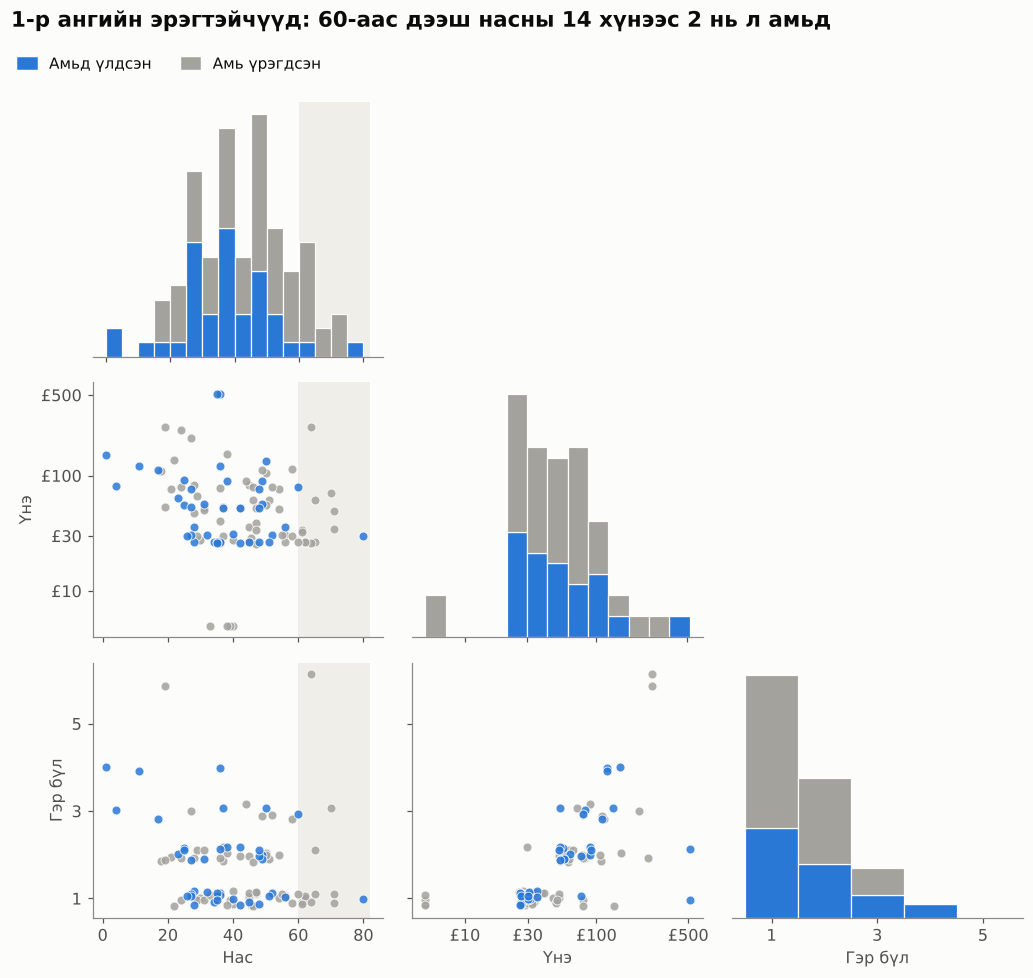

In [5]:
m = df[(df.pclass == 1) & (df.sex == 'male')].dropna(subset=['age']).copy()
rng = np.random.default_rng(1)
m['fare_l'] = np.log10(m.fare.clip(lower=5)); m['fam_j'] = m.FamilySize + rng.uniform(-.18, .18, len(m))
V = [('age', 'Нас', np.arange(0, 85, 5)), ('fare_l', 'Үнэ', np.linspace(np.log10(5), np.log10(520), 14)),
     ('fam_j', 'Гэр бүл', np.arange(0.5, 6.5, 1))]
ft = [np.log10(v) for v in [10, 30, 100, 500]]; fl = ['£10', '£30', '£100', '£500']

fig, axs = plt.subplots(3, 3, figsize=(9.5, 9))
for i, (vy, ly, by) in enumerate(V):
    for j, (vx, lx, bx) in enumerate(V):
        ax = axs[i, j]
        if j > i: ax.axis('off'); continue
        if vx == 'age': ax.axvspan(60, 82, color='#efeee9', zorder=0, lw=0)
        if i == j:
            ax.hist([m.loc[m.survived == 1, vx], m.loc[m.survived == 0, vx]], bins=bx, stacked=True,
                    color=[C_SURV, C_DIED], edgecolor=SURFACE, linewidth=0.8, zorder=2)
            ax.set_yticks([]); ax.spines['left'].set_visible(False)
        else:
            for st, col in [(0, C_DIED), (1, C_SURV)]:
                s = m[m.survived == st]
                ax.scatter(s[vx], s[vy], s=34, color=col, alpha=0.85, edgecolor=SURFACE, linewidth=0.6, zorder=3)
        if vx == 'fare_l': ax.set_xticks(ft, fl)
        if vy == 'fare_l' and i != j: ax.set_yticks(ft, fl)
        if vy == 'fam_j' and i != j: ax.set_yticks([1, 3, 5])
        if vx == 'fam_j': ax.set_xticks([1, 3, 5])
        if i == 2: ax.set_xlabel(lx)
        else: ax.set_xticklabels([])
        if j == 0 and i > 0: ax.set_ylabel(ly)
        elif i != j: ax.set_yticklabels([])
legend(fig)
header(fig, '1-р ангийн эрэгтэйчүүд: 60-аас дээш насны 14 хүнээс 2 нь л амьд', gap=0.95)
fig.subplots_adjust(left=0.09, right=0.98, bottom=0.07, hspace=0.1, wspace=0.1)
plt.show()

**Олдвор**
- **Нас**-ны диагональд цэнхэр хэсэг нас ахих тусам **шат шатаар багасна**: 18–30 насанд **41%**, 31–45 насанд **48%**, 46+ насанд **26%**, 60+ насанд **14-өөс 2**.
- **Нас × Үнэ** самбарт 60+ насны (саарал зурвас) цэгүүд £26-аас £263 хүртэлх **бүх үнийн түвшинд** бараг бүгд саарал. Өндөр үнэ (баялаг) настай эрэгтэйчүүдийг аварсангүй.
- **Үнэ × Гэр бүл** самбарт тод хэв маяг байхгүй: 1-р ангийн эрэгтэйчүүдийн хувьд үнэ, гэр бүл бараг ялгаа гаргаагүй, харин **нас** гол ялгагч болсон.
- *Тайлбарлах боломжит шалтгаан:* “эмэгтэйчүүд, хүүхдийг эхэлж” журмаар өндөр настай чинээлэг эрэгтэйчүүд залуу хамаатан, эхнэрээ завинд суулгаж өөрсдөө үлдсэн тохиолдол олон байжээ.

**Давуу тал:** Cleveland & McGill-ийн эрэмбээр хамгийн нарийн суваг болох **нийтлэг масштаб дээрх байрлал**-аар бүх хос хувьсагчийг системтэй харуулна. Нэг самбарт харагдсан хэв маягийг (нас) бусад самбарт шалгаж, “үнэ ч бас нөлөөлсөн үү?” гэсэн асуултад **хуурамч хамаарал биш** гэдгийг баталгаажуулна.

---
## Аргачлал 4: Heatmap — өнгөт матрицын дүрслэл

**Онолын ангилал:** Tominski & Schumann §3.2.1 *Table-based*; Schwabish — *Heatmap*.

| Тэмдэглэгээ | Визуал суваг |
|---|---|
| 2D хүснэгтийн нүд | мөр = анги · багана = насны бүлэг · **гэрэлтэлт** = амьд үлдсэн хувь (цайвар 0% → бараан 100%) |

*Өгөгдөл:* эрэгтэйчүүд, нас тодорхой (n = 453). Хүрээтэй нүд = олдвор.

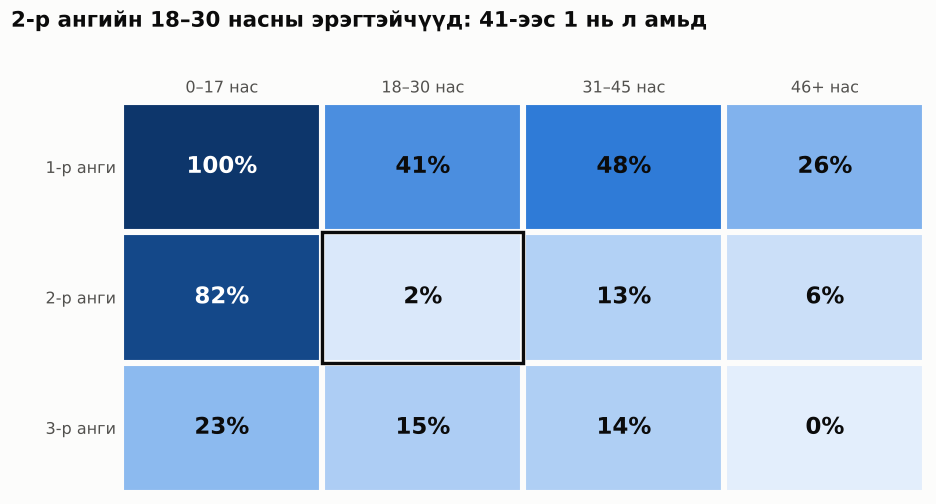

In [6]:
m = df[(df.sex == 'male')].dropna(subset=['age']).copy()
m['ag'] = pd.cut(m.age, [0, 17, 30, 45, 80], labels=['0–17', '18–30', '31–45', '46+'])
R = m.pivot_table('survived', 'pclass', 'ag', aggfunc='mean', observed=False)
N = m.pivot_table('survived', 'pclass', 'ag', aggfunc='size', observed=False)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
im = ax.imshow(R.values, cmap=BLUES, vmin=0, vmax=1, aspect='auto')
for i in range(3):
    for j in range(4):
        v = R.values[i, j]
        ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=15, fontweight='bold',
                color='white' if v > 0.55 else INK)
ax.add_patch(Rectangle((0.5, 0.5), 1, 1, fill=False, ec=INK, lw=2.2, zorder=5))   # 2-р анги, 18–30
ax.set_xticks(np.arange(-.5, 4), minor=True); ax.set_yticks(np.arange(-.5, 3), minor=True)
ax.grid(which='minor', color=SURFACE, linewidth=4); ax.tick_params(which='both', length=0)
ax.set_xticks(range(4), [f'{c} нас' for c in R.columns]); ax.xaxis.tick_top()
ax.set_yticks(range(3), ['1-р анги', '2-р анги', '3-р анги'])
for sp in ax.spines.values(): sp.set_visible(False)
header(fig, '2-р ангийн 18–30 насны эрэгтэйчүүд: 41-ээс 1 нь л амьд', gap=0.95)
fig.subplots_adjust(left=0.13, right=0.99, bottom=0.02)
plt.show()

In [7]:
# n — нүд бүрийн хүний тоо (графикт бичээгүй)
N.rename(index=lambda c: f'{c}-р анги')

ag,0–17,18–30,31–45,46+
pclass,,,,
1-р анги,4,22,33,42
2-р анги,11,41,31,16
3-р анги,43,130,65,15


**Олдвор**
- Хамгийн хүйтэн нүд **3-р анги биш, 2-р анги**: 18–30 насны 2-р ангийн эрэгтэйчүүдийн **41-ээс 1** (**2%**) амьд. Ижил насны 3-р ангийнхан **15%**, 1-р ангийнхан **41%**.
- Мөн 2-р ангийн мөрөнд хамгийн **огцом шилжилт**: хүүхэд (0–17) **82%** → залуу эрэгтэй **2%**. 2-р ангид “эмэгтэйчүүд, хүүхдийг эхэлж” журам хамгийн **хатуу** мөрдөгдсөн бололтой — хүүхдүүд бараг бүгд аврагдаж, насанд хүрсэн эрэгтэйчүүд бараг бүгд үлдсэн.
- 3-р ангид хүүхдийн давуу тал хамгийн бага (**23%**) — 3-р ангийн хөвгүүд 2-р ангийн залуу эрэгтэйчүүдээс л арай дээр байв.
- *Анхааруулга:* 1-р ангийн 0–17 насны нүд n = 4.

**Давуу тал:** 12 тоот хүснэгтийг уншихын оронд **өнгөний ялгааг урьдчилан мэдрэх** (preattentive) үйл явцаар хамгийн “хүйтэн” нүдийг агшин зуур олно. Мөр, баганын **хослол** нь 3 хувьсагчийг (анги × нас × хувь заяа) нэг нягт хүснэгтэд багтаана.

---
## Аргачлал 5: Small multiples — олон жижиг дүрслэл

**Онолын ангилал:** Tominski & Schumann §3.3.1 *Faceting*; Schwabish — *Small multiples*.

| Тэмдэглэгээ | Визуал суваг |
|---|---|
| 2 × 3 панел (мөр = хүйс, багана = анги), панел бүрт 2 багана | **урт** = амьд үлдсэн хувь (цэнхэр, 0-ээс), саарал = үлдсэн хэсэг · x = **ганцаараа / гэр бүлтэй** · бүх панел ижил масштаб |

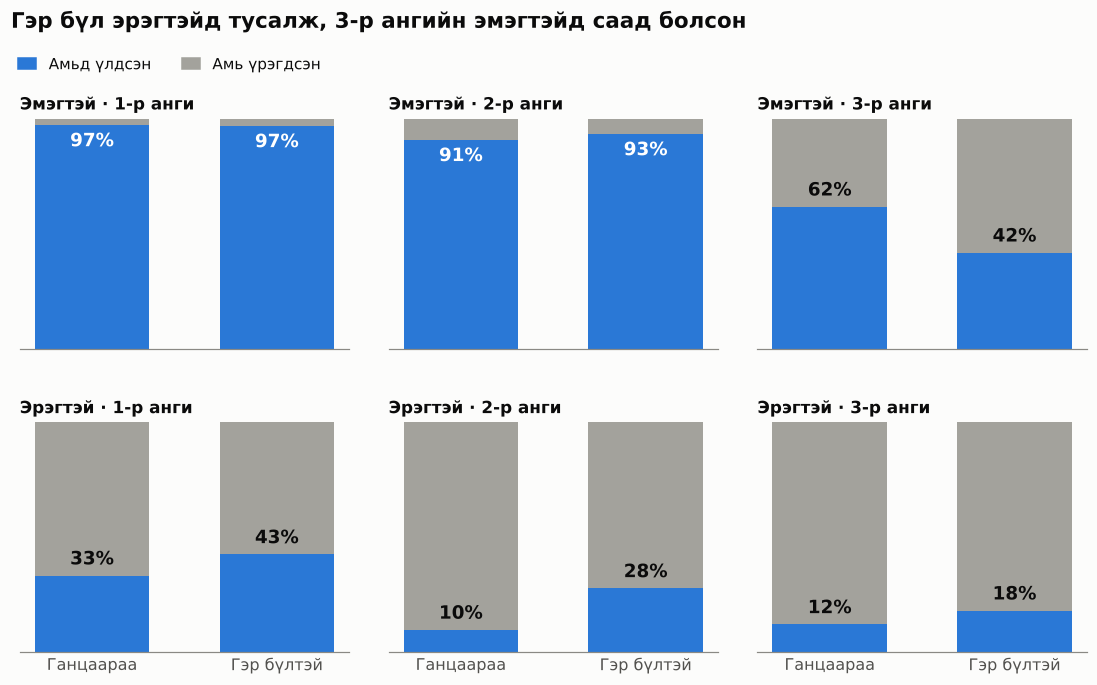

In [8]:
fig, axs = plt.subplots(2, 3, figsize=(10, 6.4), sharey=True)
for i, (s, s_mn) in enumerate([('female', 'Эмэгтэй'), ('male', 'Эрэгтэй')]):
    for j, c in enumerate([1, 2, 3]):
        ax = axs[i, j]
        g = df[(df.sex == s) & (df.pclass == c)]
        r = [g[g.alone].survived.mean(), g[~g.alone].survived.mean()]
        x = [0, 1]
        ax.bar(x, [1, 1], color=C_DIED, width=0.62, zorder=1)
        ax.bar(x, r, color=C_SURV, width=0.62, zorder=2)
        for xi, ri in zip(x, r):
            ax.text(xi, ri + 0.03 if ri < 0.85 else ri - 0.03, f'{ri:.0%}', ha='center',
                    va='bottom' if ri < 0.85 else 'top', fontsize=12, fontweight='bold',
                    color=INK if ri < 0.85 else 'white', zorder=3)
        ax.set_xticks(x, ['Ганцаараа', 'Гэр бүлтэй'] if i == 1 else ['', ''])
        ax.tick_params(axis='x', length=0)
        ax.set_ylim(0, 1); ax.set_yticks([])
        ax.spines[['left']].set_visible(False)
        ax.set_title(f'{s_mn} · {c}-р анги', fontsize=11)
legend(fig)
header(fig, 'Гэр бүл эрэгтэйд тусалж, 3-р ангийн эмэгтэйд саад болсон', gap=1.1)
fig.subplots_adjust(left=0.02, right=0.99, bottom=0.07, hspace=0.32, wspace=0.12)
plt.show()

In [9]:
pd.crosstab([df.sex, df.pclass], df.alone.map({True: 'Ганцаараа', False: 'Гэр бүлтэй'}),
            values=df.survived, aggfunc=['mean', 'size']).round(2)

mean                 size           
alone         Ганцаараа Гэр бүлтэй Ганцаараа Гэр бүлтэй
sex    pclass                                          
female 1           0.97       0.97        34         60
       2           0.91       0.93        32         44
       3           0.62       0.42        60         84
male   1           0.33       0.43        75         47
       2           0.10       0.28        72         36
       3           0.12       0.18       264         83

**Олдвор**
- **Эрэгтэй** мөрөнд гэр бүлтэй багана бүх ангид **өндөр**: 2-р ангид ганцаараа **10%** → гэр бүлтэй **28%** (≈ 3 дахин), 1-р ангид 33% → 43%. 2-р ангийн гэр бүлтэй эрэгтэйчүүдийн дөрөвний нэг нь (36-аас 9) **хөвгүүд** байсан нь энэ ялгааг хэсэгчлэн тайлбарлана.
- **Эмэгтэй** мөрөнд 1, 2-р ангид ялгаа **бараг байхгүй** (97/97%, 91/93%). Гэтэл **3-р ангид эсрэгээрээ**: ганцаараа **62%** → гэр бүлтэй **42%**. Олон хүүхэдтэй эхчүүд хүүхдүүдээ цуглуулах, хөлгийн доод давхраас гарахад цаг алдсан байх магадлалтай.
- Нэг хувьсагч (гэр бүл) **хүйс ба ангиас хамаарч эсрэг нөлөөтэй** — энэ бол харилцан үйлчлэлийн (interaction) сонгодог жишээ бөгөөд нэг нэгтгэсэн графикт харагдахгүй.

**Давуу тал:** Ижил суурь, ижил масштабтай 6 жижиг графикийг зэрэгцүүлснээр нүд **“хаана хэв маяг өөрчлөгдөв”** гэдгийг шууд олно (3-р ангийн эмэгтэй панел — ганц “урвуу” панел). Олон бүлгийг нэг графикт давхарлах “спагетти”-гээс зайлсхийнэ.

---
## Аргачлал 6: Glyph-based — Star plot (одон глиф)

**Онолын ангилал:** Tominski & Schumann §3.2.4 *Glyph-based*; Schwabish — *Radar charts*.

| Тэмдэглэгээ | Визуал суваг |
|---|---|
| 2D олон өнцөгт глиф (нэг боомт = нэг од) | 4 цацрагийн **урт**, бүгд 0–100%: Эмэгтэй %, 1-р анги %, Ганцаараа %, **Амьд үлдсэн %** (цэнхэр цэг) · тасархай = нийт зорчигч |

Бүх тэнхлэг ижил нэгжтэй (%) тул нормчлол шаардлагагүй — уншихад хялбар.

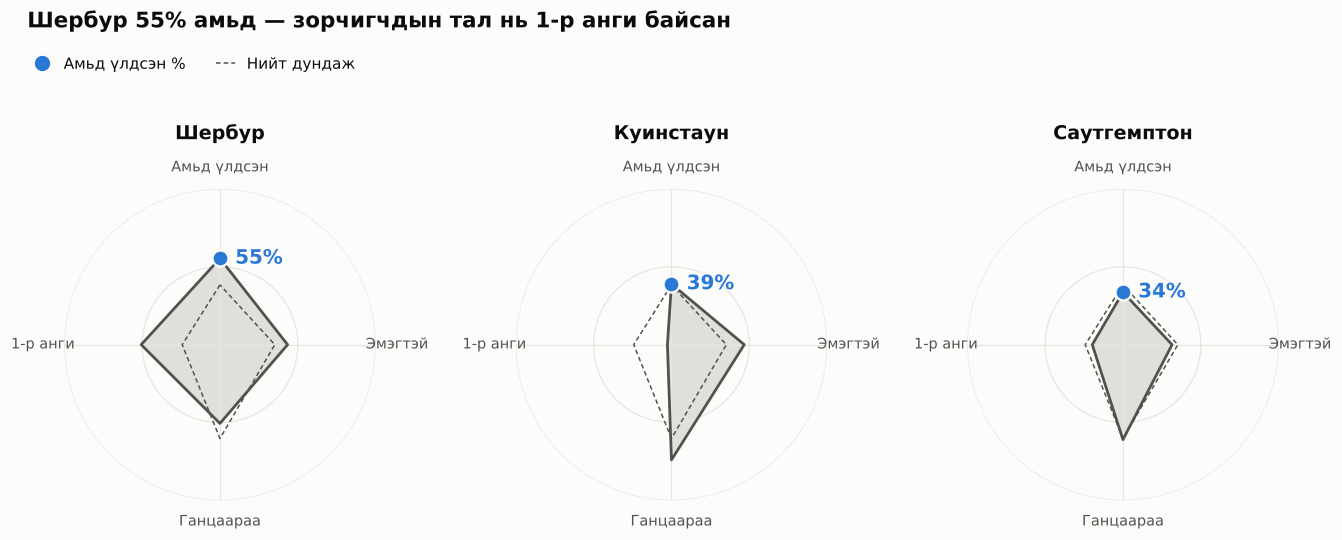

In [10]:
prof = (df.dropna(subset=['port']).groupby('port')
          .agg(fem=('sex', lambda s: (s == 'female').mean()), c1=('pclass', lambda s: (s == 1).mean()),
               alone=('alone', 'mean'), surv=('survived', 'mean'), n=('survived', 'size')))
allp = pd.Series({'fem': (df.sex == 'female').mean(), 'c1': (df.pclass == 1).mean(),
                  'alone': df.alone.mean(), 'surv': df.survived.mean()})
AX = [('surv', 'Амьд үлдсэн'), ('c1', '1-р анги'), ('alone', 'Ганцаараа'), ('fem', 'Эмэгтэй')]
ang = np.linspace(0, 2 * np.pi, len(AX), endpoint=False) + np.pi / 2
close = lambda a: np.r_[a, a[:1]]

fig, axs = plt.subplots(1, 3, figsize=(12, 5.4), subplot_kw={'projection': 'polar'})
for ax, p in zip(axs, ['Шербур', 'Куинстаун', 'Саутгемптон']):
    r = np.array([prof.loc[p, k] for k, _ in AX]); rr = np.array([allp[k] for k, _ in AX])
    ax.plot(close(ang), close(rr), color=INK2, lw=1, ls=(0, (3, 2)))
    ax.fill(close(ang), close(r), color='#c9c8c3', alpha=0.55)
    ax.plot(close(ang), close(r), color=INK2, lw=1.8)
    ax.scatter([ang[0]], [r[0]], s=110, color=C_SURV, zorder=5, edgecolor=SURFACE, linewidth=1.5)
    ax.annotate(f'{r[0]:.0%}', (ang[0], r[0]), xytext=(10, 0), textcoords='offset points',
                color=C_SURV, fontsize=13, fontweight='bold', ha='left', va='center')
    ax.set_ylim(0, 1); ax.set_yticks([0.5, 1]); ax.set_yticklabels([])
    ax.set_xticks(ang, [l for _, l in AX], fontsize=9.5, color=INK2)
    ax.grid(color=GRID); ax.spines['polar'].set_visible(False)
    ax.text(0.5, 1.16, p, transform=ax.transAxes, ha='center', fontsize=12.5, fontweight='bold')
legend(fig, [Line2D([], [], color=C_SURV, marker='o', ls='', markersize=9, label='Амьд үлдсэн %'),
             Line2D([], [], color=INK2, lw=1, ls=(0, (3, 2)), label='Нийт дундаж')])
header(fig, 'Шербур 55% амьд — зорчигчдын тал нь 1-р анги байсан', gap=1.35)
fig.subplots_adjust(left=0.04, right=0.96, bottom=0.08, wspace=0.45)
plt.show()

In [11]:
prof.rename(columns={'fem': 'Эмэгтэй', 'c1': '1-р анги', 'alone': 'Ганцаараа', 'surv': 'Амьд үлдсэн'}).round(2)

,Эмэгтэй,1-р анги,Ганцаараа,Амьд үлдсэн,n
port,,,,,
Куинстаун,0.47,0.03,0.74,0.39,77
Саутгемптон,0.32,0.20,0.61,0.34,644
Шербур,0.43,0.51,0.51,0.55,168


**Олдвор**
- **Шербурын** од “1-р анги” цацрагаараа хамгийн урт (**51%**) — Францын энэ боомтоос суусан зорчигчдын тал нь баян 1-р ангийнхан байсан. Тиймээс амьд үлдэлт **55%** (нийт 38%).
- **Куинстауны** од эсрэг хэлбэртэй: 1-р анги бараг тэг (**3%**), гэвч **эмэгтэй** (47%) ба **ганцаараа** (74%) цацраг урт — ядуу ч ганцаараа явсан залуу эмэгтэйчүүд олон. Иймээс 94% нь 3-р анги байтал Саутгемптоноос **илүү** амьд үлдсэн (39% vs 34%).
- **Саутгемптоны** од “Эмэгтэй” цацрагаараа хамгийн богино (**32%**) — ганцаараа явсан эрэгтэйчүүд давамгайлсан → хамгийн бага амьд үлдэлт (**34%**).
- Гурван одыг зэрэгцүүлэхэд **“боомт өөрөө нөлөөлсөн”** биш, **боомт бүрийн зорчигчдын бүрэлдэхүүн** өөр байсан нь ялгааг тайлбарлаж байгааг шууд ойлгоно.

**Давуу тал:** Нэг бүлгийн олон хувьсагчийг **нэг биет дүрс** болгож, хүний хараа **хэлбэрийг** хурдан танидгийг ашиглана. 3 боомтын “хувийн шинж” (profile)-ийг тоон хүснэгт уншилгүйгээр **дүрсээр** харьцуулна.

---
## Аргачлал 7: Pixel-based — пикселэн дүрслэл (Keim)

**Онолын ангилал:** Tominski & Schumann §3.2.5 *Pixel-based* (Keim & Kriegel).

| Тэмдэглэгээ | Визуал суваг |
|---|---|
| 0D пиксел (нэг зорчигч = цонх бүрт нэг пиксел) | **дараалал**: бүх 891 зорчигчийг үнээр буурахаар эрэмбэлж 30 × 30 торлолд мөр мөрөөр (зүүн дээд = хамгийн үнэтэй) · **өнгө**: Үнэ, Анги — ягаан-хөхийн гэрэлтэлт; Хүйс — цайвар/бараан; Хувь заяа — цэнхэр/саарал |

Хүрээтэй мөр = £0 үнэтэй тасалбар (15 хүн). Сүүлийн 9 нүд хоосон.

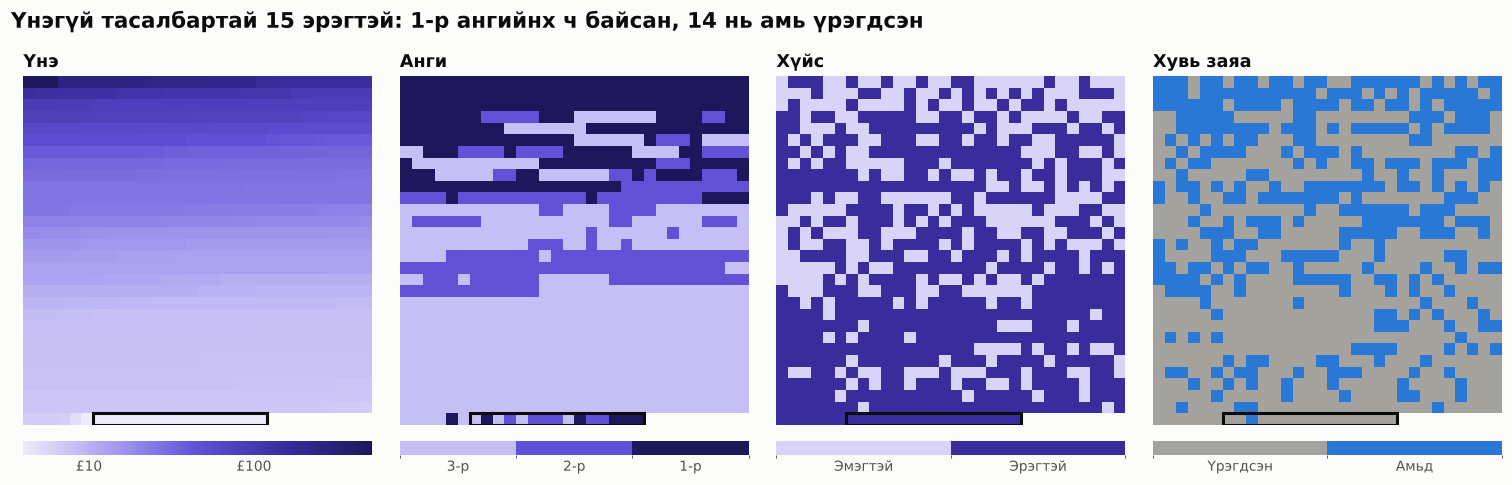

In [12]:
d7 = df.sort_values('fare', ascending=False, kind='stable').reset_index(drop=True)
W = 30; H = 30
def grid(v):
    a = np.full(W * H, np.nan); a[:len(v)] = v
    return a.reshape(H, W)

zero = np.where(d7.fare.values == 0)[0]
z0, z1 = zero.min(), zero.max()                     # £0 мөрийн байрлал
win = [
    ('Үнэ', grid(np.log10(d7.fare.clip(lower=4))), VIOLET, Normalize(np.log10(4), np.log10(520)),
     ([np.log10(10), np.log10(100)], ['£10', '£100'])),
    ('Анги', grid(4 - d7.pclass), ListedColormap(['#c6bff5', '#6250d6', '#1f175c']), BoundaryNorm([.5, 1.5, 2.5, 3.5], 3),
     ([1, 2, 3], ['3-р', '2-р', '1-р'])),
    ('Хүйс', grid((d7.sex == 'male').astype(float)), ListedColormap(['#d9d4f7', '#3a2c9c']), BoundaryNorm([-.5, .5, 1.5], 2),
     ([0, 1], ['Эмэгтэй', 'Эрэгтэй'])),
    ('Хувь заяа', grid(d7.survived.astype(float)), ListedColormap([C_DIED, C_SURV]), BoundaryNorm([-.5, .5, 1.5], 2),
     ([0, 1], ['Үрэгдсэн', 'Амьд'])),
]
fig, axs = plt.subplots(1, 4, figsize=(14, 4.3))
for ax, (title, A, cmap, nrm, (tv, tl)) in zip(axs, win):
    cm = cmap.copy(); cm.set_bad(SURFACE)
    im = ax.imshow(np.ma.masked_invalid(A), cmap=cm, norm=nrm, interpolation='nearest')
    ax.add_patch(Rectangle((z0 % W - 0.5, z0 // W - 0.5), z1 - z0 + 1, 1, fill=False, ec=INK, lw=2, zorder=5))
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_title(title, fontsize=11.5)
    cb = fig.colorbar(im, ax=ax, orientation='horizontal', fraction=0.05, pad=0.04, aspect=25)
    cb.outline.set_visible(False); cb.ax.tick_params(labelsize=9, length=0); cb.set_ticks(tv); cb.set_ticklabels(tl)
header(fig, 'Үнэгүй тасалбартай 15 эрэгтэй: 1-р ангийнх ч байсан, 14 нь амь үрэгдсэн', gap=0.55)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.02, wspace=0.08)
plt.show()

In [13]:
free = df[df.fare == 0]
print(f'£0 тасалбар: {len(free)} хүн · эрэгтэй {free.sex.eq("male").mean():.0%} · ганцаараа {free.alone.mean():.0%} · '
      f'боомт: {free.port.unique().tolist()} · амьд: {free.survived.sum()}')
free.groupby('pclass').survived.agg(n='size', amid='sum').rename(columns={'amid': 'амьд'})

£0 тасалбар: 15 хүн · эрэгтэй 100% · ганцаараа 100% · боомт: ['Саутгемптон'] · амьд: 1


,n,амьд
pclass,,
1,5,0
2,6,0
3,4,1


**Олдвор**
- Эрэмбийн **хамгийн төгсгөлд** (хүрээтэй мөр) “Хүйс” цонхонд **бүх 15 пиксел бараан** (эрэгтэй), “Хувь заяа” цонхонд **ганц л цэнхэр** пиксел — £0 тасалбартай 15 хүний **14** нь амь үрэгдсэн (**7%**).
- Хамгийн гайхалтай нь “Анги” цонх: хамгийн хямд мөрөнд **бараан (1-р анги)** пиксел гарч ирдэг — үнэгүй тасалбартай хүмүүсийн **5 нь 1-р, 6 нь 2-р** ангийнх. Тэд бүгд **ганцаараа**, бүгд **Саутгемптоноос** суусан. Энэ нь тэд жирийн зорчигч биш, хөлөг онгоцны компанийн ажилтан эсвэл баталгааны багийн гишүүд байсан байх магадлалтайг илтгэнэ.
- 1-р ангийн 5 “үнэгүй” зорчигчийн **нэг нь ч** амьд үлдээгүй — 1-р ангийн эрэгтэйчүүдийн дундаж 37%-тай харьцуулахад онцгой.
- Ерөнхий хэв маяг: дээд мөрүүд (үнэтэй) “Хувь заяа” цонхонд цэнхэр давамгай, доош (хямд) саарал давамгай; “Хүйс” цонхны доод хэсэг бараан (эрэгтэй) пикселээр дүүрэн.

**Давуу тал:** Нэг утга = нэг пиксел тул **891 зорчигчийн бүх утгыг** нэгтгэлгүй, давхцалгүй харуулна. Бүх цонх **ижил эрэмбэ**-тэй тул эрэмбийн хязгаарт байгаа **гаж утгын бүлэг** (энд £0 тасалбар) бусад хувьсагчаар ямар байгааг цонх хооронд нүдээр дагаж шууд илрүүлнэ — нэгтгэсэн график энэ 15 хүнийг харуулахгүй.

---
## Нэгдсэн дүгнэлт

| Аргачлал | Tominski & Schumann | Яагаад энэ олдворт тохирсон бэ | Олдвор |
|---|---|---|---|
| Mosaic | §3.2.6 Nested | 3 ангиллын хувьсагчийн хувь **ба** тоо | Куинстауны 3-р ангийн эмэгтэйчүүд 73% vs Саутгемптон 38% |
| Parallel coordinates | §3.2.3 Polyline | хөрш тэнхлэгийн **корреляц** | 3-р ангид үнэ = гэр бүлийн хэмжээ; 5+ гэр бүл 7% |
| SPLOM | §3.2.2 Bivariate | бүх хосыг шалгаж **ялгагч хувьсагчийг** олох | 1-р ангийн эрэгтэйчүүдэд нас шийдвэрлэсэн; 60+ 14-өөс 2 |
| Heatmap | §3.2.1 Table | хамгийн **“хүйтэн” нүдийг** агшин зуур олох | 2-р ангийн 18–30 насны эрэгтэйчүүд 2% |
| Small multiples | §3.3.1 Faceting | **урвуу** панелийг илрүүлэх | Гэр бүл эрэгтэйд тус, 3-р ангийн эмэгтэйд саад |
| Star glyph | §3.2.4 Glyph | бүлгийн **профиль-ыг дүрсээр** харьцуулах | Боомтын ялгааг зорчигчдын бүрэлдэхүүн тайлбарлана |
| Pixel-based | §3.2.5 Pixel | **бүх мөрийг** харж гаж бүлгийг олох | £0 тасалбартай 15 эрэгтэй, 1-р ангийнх ч, 14 нь үрэгдсэн |

**Гол санаа.** “Эмэгтэйчүүд ба баячууд амьд үлдсэн” гэдэг нь зөвхөн **дунджаар** үнэн. Олон хувьсагчийг зэрэг дүрслэхэд энэ дүрэм **хаана эвдэрч** байгааг харж болно: ядуу ч Куинстауны эмэгтэйчүүд амьд үлдсэн, “үнэтэй” ч 3-р ангийн том гэр бүлүүд үрэгдсэн, баян ч настай эрэгтэйчүүд үлдсэн, үнэгүй ч 1-р ангийн зорчигчид байсан. Аргачлал бүр өөр төрлийн “эвдрэлийг” хамгийн сайн илрүүлдэг.